<a href="https://colab.research.google.com/github/kinyanjui23/Physics-Informed-Neural-Network/blob/main/pv1_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Conventional Physics-Informed Neural Network (PINN)

##  Importing Libraries

This section imports the libraries required to construct, train, and evaluate the conventional Physics-Informed Neural Network (PINN).

- **PyTorch:** defines the neural network, performs automatic differentiation, and optimizes the model parameters.
- **NumPy:** supports numerical calculations and manipulation of evaluation results.
- **Matplotlib:** visualizes the solution, absolute error, and convergence behavior.
- **Time:** measures computational time during training and evaluation.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

## 2. Computational Domain

We consider a rhombus-shaped computational domain defined by
\begin{equation}
Ω=\{(x,y) R^2 :|x|+|y|<1\}.
\end{equation}

The boundary of the domain is

\begin{equation}
∂Ω=\{(x,y):|x|+|y|=1\}.
\end{equation}

The four vertices are (0,1), (1,0), (0,-1), and (-1,0). The same spatial domain will be used for the Poisson, heat, and wave equations to ensure a consistent benchmark for comparing PINN and HFD-PINN.

## 2.1 Signed Distance Function

The Signed Distance Function (SDF) is defined as

\begin{equation}
\phi(x,y)=\frac{|x|+|y|-1}{\sqrt{2}}.
\end{equation}

For points inside the rhombus, the SDF is negative; on the boundary, it is zero; and outside the rhombus, it is positive. For interior points, its magnitude gives the Euclidean distance to the nearest edge.

In [2]:
def sdf(x, y):
    return (torch.abs(x) + torch.abs(y) - 1.0) / np.sqrt(2.0)

We'll use one spatial function for all three PDEs:
\begin{equation}
{g(x,y)=[1-(x+y)^2][1-(x-y)^2]}.
\end{equation}

It satisfies \(g=0\) on the rhombus boundary. Its Laplacian is
\begin{equation}
{g_{xx}+g_{yy}=-8(1-x^2-y^2)}.
\end{equation}

In [3]:
def g(x, y):
    return (1.0 - (x + y)**2) * (1.0 - (x - y)**2)

1. **Poisson equation**
   
$$
-\Delta u=f_P(x,y),\qquad u|_{\partial\Omega}=0.
$$

Exact solution:
$$
u_P(x,y)=g(x,y).
$$

Forcing term:
$$
f_P(x,y)=8(1-x^2-y^2).
$$


2. **Heat equation**
$$
u_t=\Delta u+f_H(x,y,t).
$$

Exact solution:
$$
u_H(x,y,t)=e^{-t}g(x,y).
$$

Forcing term:
$$
f_H=e^{-t}\left[-g+8(1-x^2-y^2)\right].
$$

Initial condition: $$ (u_H(x,y,0)=g(x,y)). Boundary condition: (u_H=0). $$


3. **Wave equation**
$$
u_{tt}=\Delta u+f_W(x,y,t).
$$

Exact solution:
$$
u_W(x,y,t)=g(x,y)\cos t.
$$

Forcing term:
$$
f_W=\cos t\left[-g+8(1-x^2-y^2)\right].
$$

Initial displacement:$$ (u_W(x,y,0)=g(x,y)). Initial velocity: (u_t(x,y,0)=0). Boundary condition: (u_W=0).$$

In [4]:
def exact_poisson(x, y):
    return g(x, y)


def exact_heat(x, y, t):
    return torch.exp(-t) * g(x, y)


def exact_wave(x, y, t):
    return g(x, y) * torch.cos(t)

*Creating the Neural Network*

In [5]:
class PINN(nn.Module):
    def __init__(self, input_dim, hidden_dim=64, hidden_layers=4):
        super().__init__()

        layers = [nn.Linear(input_dim, hidden_dim), nn.Tanh()]

        for _ in range(hidden_layers - 1):
            layers.extend([nn.Linear(hidden_dim, hidden_dim), nn.Tanh()])

        layers.append(nn.Linear(hidden_dim, 1))
        self.network = nn.Sequential(*layers)

    def forward(self, X):
        return self.network(X)

Automatic differentiation calculates derivatives of the neural network output with respect to its inputs.

For the Poisson equation, we need
$$
u_x=\frac{\partial u_\theta}{\partial x},
\qquad
u_y=\frac{\partial u_\theta}{\partial y},
$$

and the second derivatives
$$
u_{xx}=\frac{\partial^2u_\theta}{\partial x^2},
\qquad
u_{yy}=\frac{\partial^2u_\theta}{\partial y^2}.
$$

For the heat equation, we additionally need
$$
u_t=\frac{\partial u_\theta}{\partial t}.
$$
For the wave equation, we need the second time derivative
$$
u_{tt}=\frac{\partial^2u_\theta}{\partial t^2}.
$$

We use PyTorch's torch.autograd.grad() to calculate these derivatives. Setting create_graph=True allows PyTorch to retain the derivative computation so that the PDE residual can contribute gradients during network training.

In [6]:
def derivatives(u, X):
  grad_u = torch.autograd.grad(u, X, grad_outputs=torch.ones_like(u), create_graph=True)[0]
  u_x = grad_u[:, 0:1]
  u_y = grad_u[:, 1:2]
  grad_ux = torch.autograd.grad(u_x, X, grad_outputs=torch.ones_like(u_x), create_graph=True)[0]
  grad_uy = torch.autograd.grad(u_y, X, grad_outputs=torch.ones_like(u_y), create_graph=True)[0]
  u_xx = grad_ux[:, 0:1]
  u_yy = grad_uy[:, 1:2]
  if X.shape[1]==2:
    return u_x, u_y, u_xx, u_yy

  u_t = grad_u[:, 2:3]
  grad_ut = torch.autograd.grad(u_t, X, grad_outputs=torch.ones_like(u_t), create_graph=True)[0]
  u_tt = grad_ut[:, 2:3]
  return u_x, u_y, u_xx, u_yy, u_t, u_tt

**PDE residuals**


The PDE residual measures how well the neural-network approximation satisfies the governing equation at a collocation point.

For the Poisson equation,
$$
-\Delta u=f_P(x,y),
$$

the residual is
$$
\boxed{r_P=-(u_{xx}+u_{yy})-f_P}.
$$

For the heat equation,
$$
u_t=\Delta u+f_H(x,y,t),
$$

the residual is
$$
\boxed{r_H=u_t-(u_{xx}+u_{yy})-f_H}.
$$

For the wave equation,
$$
u_{tt}=\Delta u+f_W(x,y,t),
$$

the residual is
$$
\boxed{r_W=u_{tt}-(u_{xx}+u_{yy})-f_W}.
$$
For an exact solution, the corresponding residual is zero, apart from numerical precision. During PINN training, we minimize the squared residuals

In [7]:
def poisson_residual(model, X):
    X = X.detach().clone().requires_grad_(True)
    u = model(X)
    _, _, u_xx, u_yy = derivatives(u, X)

    x = X[:, 0:1]
    y = X[:, 1:2]
    f = 8.0 * (1.0 - x**2 - y**2)

    return -(u_xx + u_yy) - f


def heat_residual(model, X):
    X = X.detach().clone().requires_grad_(True)
    u = model(X)
    _, _, u_xx, u_yy, u_t, _ = derivatives(u, X)

    x = X[:, 0:1]
    y = X[:, 1:2]
    t = X[:, 2:3]

    forcing = torch.exp(-t) * (
        -g(x, y) + 8.0 * (1.0 - x**2 - y**2)
    )

    return u_t - (u_xx + u_yy) - forcing


def wave_residual(model, X):
    X = X.detach().clone().requires_grad_(True)
    u = model(X)
    _, _, u_xx, u_yy, _, u_tt = derivatives(u, X)

    x = X[:, 0:1]
    y = X[:, 1:2]
    t = X[:, 2:3]

    forcing = torch.cos(t) * (
        -g(x, y) + 8.0 * (1.0 - x**2 - y**2)
    )

    return u_tt - (u_xx + u_yy) - forcing

In [8]:
def generate_spatial_points(N_interior=5000, N_boundary=800):
    interior_points = []
    total = 0

    while total < N_interior:
        candidates = 2.0 * torch.rand(N_interior, 2) - 1.0
        valid = candidates[
            (torch.abs(candidates[:, 0]) +
             torch.abs(candidates[:, 1])) < 1.0
        ]

        interior_points.append(valid)
        total += len(valid)

    X_interior = torch.cat(interior_points, dim=0)[:N_interior]

    vertices = torch.tensor([
        [0.0, 1.0],
        [1.0, 0.0],
        [0.0, -1.0],
        [-1.0, 0.0]
    ])

    n_edge = N_boundary // 4
    edges = []

    for i in range(4):
        a = vertices[i]
        b = vertices[(i + 1) % 4]
        r = torch.rand(n_edge, 1)
        edges.append(a + r * (b - a))

    X_boundary = torch.cat(edges, dim=0)

    return X_interior, X_boundary

*Add time coordinates for heat and wave*

For the heat and wave equations, we add a time coordinate to each spatial point. We'll use \(T=1\) for the initial benchmark.

In [9]:
def add_time(X, T=1.0):
    t = T * torch.rand(len(X), 1)
    return torch.cat([X, t], dim=1)

loss function
The total loss consists of the PDE residual loss and the boundary-condition loss. For the heat and wave equations, we also include the initial-condition loss.

For Poisson:
$$
\mathcal L_P=\mathcal L_{\mathrm{PDE}}+\mathcal L_{\mathrm{BC}}.
$$

For heat:
$$
\mathcal L_H=\mathcal L_{\mathrm{PDE}}+
\mathcal L_{\mathrm{BC}}+\mathcal L_{\mathrm{IC}}.
$$

For wave:
$$
\mathcal L_W=\mathcal L_{\mathrm{PDE}}+
\mathcal L_{\mathrm{BC}}+\mathcal L_{\mathrm{IC}}+
\mathcal L_{\mathrm{IV}},
$$
where $$ (\mathcal L_{\mathrm{IV}}) enforces the initial velocity (u_t(x,y,0)=0) $$. We use the mean squared error for each component.

In [10]:
def poisson_loss(model, X_interior, X_boundary):
    residual = poisson_residual(model, X_interior)
    loss_pde = torch.mean(residual**2)

    loss_boundary = torch.mean(model(X_boundary)**2)

    return loss_pde + loss_boundary


def heat_loss(model, X_interior, X_boundary, X_initial):
    residual = heat_residual(model, X_interior)
    loss_pde = torch.mean(residual**2)

    loss_boundary = torch.mean(model(X_boundary)**2)

    loss_initial = torch.mean(
        (model(X_initial) - g(
            X_initial[:, 0:1], X_initial[:, 1:2]
        ))**2
    )

    return loss_pde + loss_boundary + loss_initial


def wave_loss(model, X_interior, X_boundary, X_initial):
    residual = wave_residual(model, X_interior)
    loss_pde = torch.mean(residual**2)

    loss_boundary = torch.mean(model(X_boundary)**2)

    loss_initial = torch.mean(
        (model(X_initial) - g(
            X_initial[:, 0:1], X_initial[:, 1:2]
        ))**2
    )

    X_initial = X_initial.detach().clone().requires_grad_(True)
    u_initial = model(X_initial)
    u_t = derivatives(u_initial, X_initial)[4]

    loss_initial_velocity = torch.mean(u_t**2)

    return (
        loss_pde + loss_boundary +
        loss_initial + loss_initial_velocity
    )

In [11]:
# Spatial points
X_interior, X_boundary = generate_spatial_points(5000, 800)

# Poisson training data
X_P = X_interior
X_P_boundary = X_boundary

# Heat and wave space-time interior points
X_HT = add_time(X_interior, T=1.0)

# Boundary points with sampled time
X_boundary_time = add_time(X_boundary, T=1.0)

# Initial points at t = 0
X_initial = torch.cat([
    X_interior,
    torch.zeros(len(X_interior), 1)
], dim=1)

In [12]:
#training

In [13]:
def train_model(model, loss_function, data, epochs=5000, lr=1e-3):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = []

    start_time = time.perf_counter()

    for epoch in range(epochs):
        optimizer.zero_grad()
        loss = loss_function(model, *data)
        loss.backward()
        optimizer.step()

        history.append(loss.item())

        if (epoch + 1) % 500 == 0:
            print(f"Epoch {epoch + 1}: Loss = {loss.item():.6e}")

    training_time = time.perf_counter() - start_time

    return history, training_time

In [14]:
# Initialize models
poisson_model = PINN(input_dim=2)
heat_model = PINN(input_dim=3)
wave_model = PINN(input_dim=3)

# Train Poisson
poisson_history, poisson_time = train_model(
    poisson_model,
    poisson_loss,
    (X_P, X_P_boundary)
)

# Train heat
heat_history, heat_time = train_model(
    heat_model,
    heat_loss,
    (X_HT, X_boundary_time, X_initial)
)

# Train wave
wave_history, wave_time = train_model(
    wave_model,
    wave_loss,
    (X_HT, X_boundary_time, X_initial)
)

Epoch 500: Loss = 4.985187e-02
Epoch 1000: Loss = 4.573444e-02
Epoch 1500: Loss = 4.329658e-02
Epoch 2000: Loss = 3.782880e-02
Epoch 2500: Loss = 1.832125e-02
Epoch 3000: Loss = 5.598878e-03
Epoch 3500: Loss = 1.914847e-02
Epoch 4000: Loss = 6.263723e-04
Epoch 4500: Loss = 8.974933e-04
Epoch 5000: Loss = 2.311286e-04
Epoch 500: Loss = 3.113317e-02
Epoch 1000: Loss = 2.466131e-02
Epoch 1500: Loss = 1.134601e-02
Epoch 2000: Loss = 3.695731e-03
Epoch 2500: Loss = 2.067268e-03
Epoch 3000: Loss = 9.106244e-04
Epoch 3500: Loss = 5.927586e-04
Epoch 4000: Loss = 4.186585e-04
Epoch 4500: Loss = 1.121991e-03
Epoch 5000: Loss = 2.566439e-04
Epoch 500: Loss = 5.118084e-02
Epoch 1000: Loss = 4.111554e-02
Epoch 1500: Loss = 3.042849e-02
Epoch 2000: Loss = 1.062200e-02
Epoch 2500: Loss = 3.130488e-03
Epoch 3000: Loss = 1.557620e-03
Epoch 3500: Loss = 9.854134e-04
Epoch 4000: Loss = 3.742570e-03
Epoch 4500: Loss = 1.094082e-02
Epoch 5000: Loss = 4.667193e-04


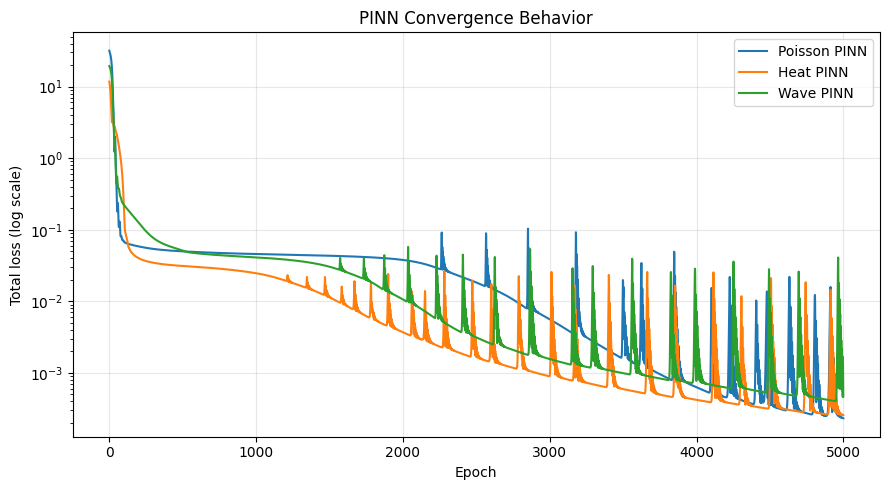

In [15]:
plt.figure(figsize=(9, 5))

plt.semilogy(poisson_history, label="Poisson PINN")
plt.semilogy(heat_history, label="Heat PINN")
plt.semilogy(wave_history, label="Wave PINN")

plt.xlabel("Epoch")
plt.ylabel("Total loss (log scale)")
plt.title("PINN Convergence Behavior")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [16]:
def evaluate_model(model, X, exact_solution):
    model.eval()

    with torch.no_grad():
        exact = exact_solution(
            X[:, 0:1],
            X[:, 1:2]
        ) if X.shape[1] == 2 else exact_solution(
            X[:, 0:1],
            X[:, 1:2],
            X[:, 2:3]
        )

        predicted = model(X)

        relative_l2 = (
            torch.sqrt(torch.sum((predicted - exact)**2))
            / torch.sqrt(torch.sum(exact**2))
        )


    return (
        relative_l2.item(),
    )

In [17]:
def evaluate_model(model, X, exact_solution):
    model.eval()

    with torch.no_grad():
        exact = exact_solution(
            X[:, 0:1],
            X[:, 1:2]
        ) if X.shape[1] == 2 else exact_solution(
            X[:, 0:1],
            X[:, 1:2],
            X[:, 2:3]
        )

        predicted = model(X)

        relative_l2 = (
            torch.sqrt(torch.sum((predicted - exact)**2))
            / torch.sqrt(torch.sum(exact**2))
        )

        rmse = torch.sqrt(torch.mean((predicted - exact)**2))
        max_error = torch.max(torch.abs(predicted - exact))

    return (
        relative_l2.item(),
        rmse.item(),
        max_error.item()
    )

In [18]:
# New spatial test points
X_test, _ = generate_spatial_points(
    N_interior=2000,
    N_boundary=800
)

# Poisson test points
X_test_poisson = X_test

# Heat and wave test points, including random times
X_test_heat = add_time(X_test, T=1.0)
X_test_wave = add_time(X_test, T=1.0)

# Evaluate all three models
poisson_errors = evaluate_model(
    poisson_model, X_test_poisson, exact_poisson
)

heat_errors = evaluate_model(
    heat_model, X_test_heat, exact_heat
)

wave_errors = evaluate_model(
    wave_model, X_test_wave, exact_wave
)

print("Poisson (Relative L2, RMSE, Max Error):", poisson_errors)
print("Heat    (Relative L2, RMSE, Max Error):", heat_errors)
print("Wave    (Relative L2, RMSE, Max Error):", wave_errors)

Poisson (Relative L2, RMSE, Max Error): (0.005605295766144991, 0.0029890125151723623, 0.022667182609438896)
Heat    (Relative L2, RMSE, Max Error): (0.010057078674435616, 0.003547375788912177, 0.01549072377383709)
Wave    (Relative L2, RMSE, Max Error): (0.029033180326223373, 0.013096602633595467, 0.03325700759887695)


In [19]:
def plot_comparison(model, exact_solution, time_value=None):
    # Create a grid over the square containing the rhombus
    x = torch.linspace(-1, 1, 150)
    y = torch.linspace(-1, 1, 150)
    X, Y = torch.meshgrid(x, y, indexing="ij")

    # Keep only points inside the rhombus
    inside = (torch.abs(X) + torch.abs(Y)) < 1.0

    x_points = X[inside].reshape(-1, 1)
    y_points = Y[inside].reshape(-1, 1)

    if time_value is None:
        test_points = torch.cat([x_points, y_points], dim=1)
        exact = exact_solution(x_points, y_points)
    else:
        t_points = torch.full_like(x_points, time_value)
        test_points = torch.cat(
            [x_points, y_points, t_points], dim=1
        )
        exact = exact_solution(x_points, y_points, t_points)

    # Predict using the trained PINN
    model.eval()
    with torch.no_grad():
        predicted = model(test_points)

    error = torch.abs(predicted - exact)

    # Put values back onto the grid for contour plotting
    exact_grid = np.full(X.shape, np.nan)
    predicted_grid = np.full(X.shape, np.nan)
    error_grid = np.full(X.shape, np.nan)

    exact_grid[inside.numpy()] = exact.numpy().ravel()
    predicted_grid[inside.numpy()] = predicted.numpy().ravel()
    error_grid[inside.numpy()] = error.numpy().ravel()

    # Plot the three comparisons
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    plots = [
        (exact_grid, "Exact solution"),
        (predicted_grid, "PINN prediction"),
        (error_grid, "Absolute error")
    ]

    for ax, (values, title) in zip(axes, plots):
        contour = ax.contourf(X.numpy(), Y.numpy(), values, levels=30)
        fig.colorbar(contour, ax=ax)
        ax.set_title(title)
        ax.set_xlabel("x")
        ax.set_ylabel("y")
        ax.set_aspect("equal")

    if time_value is None:
        fig.suptitle("Poisson PINN: Exact vs Predicted")
    else:
        fig.suptitle(f"PINN: Exact vs Predicted at t = {time_value}")

    plt.tight_layout()
    plt.show()

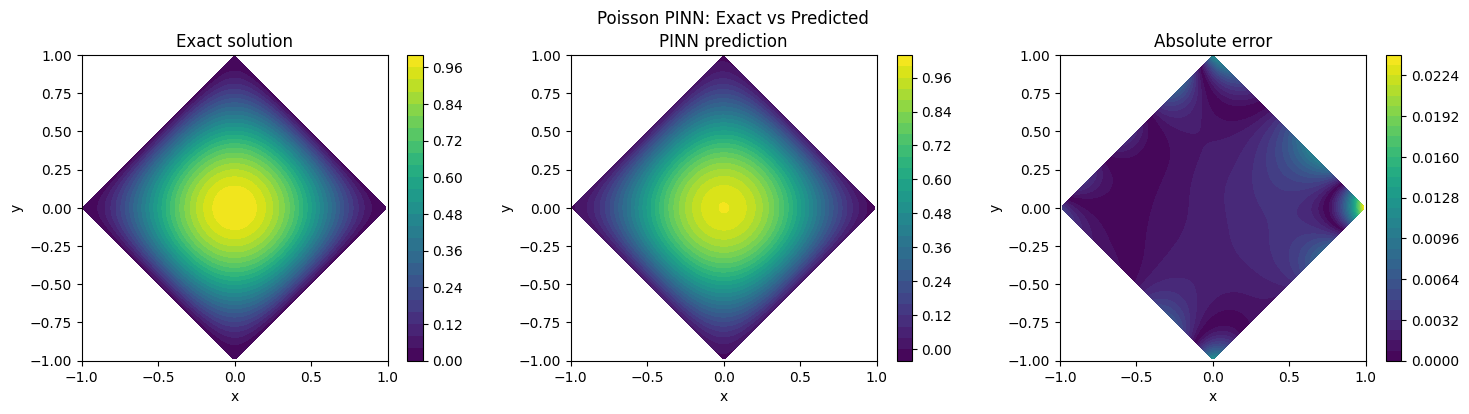

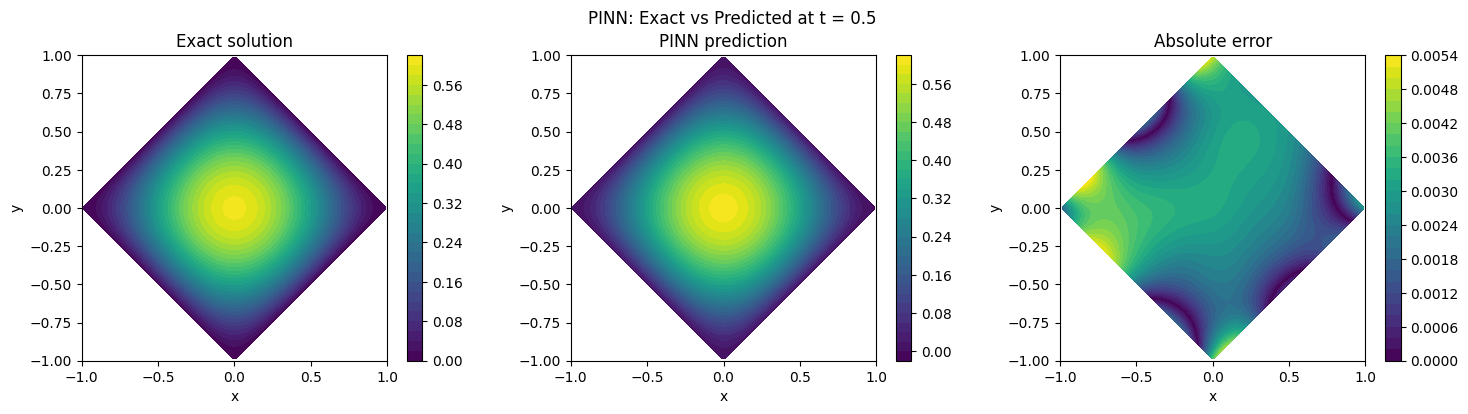

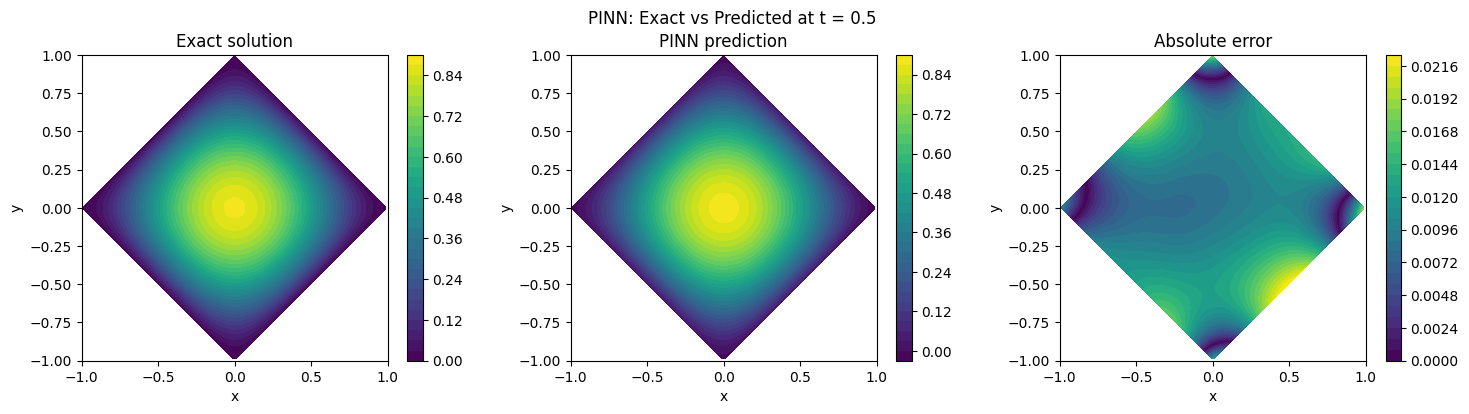

In [20]:
# Poisson equation
plot_comparison(
    poisson_model,
    exact_poisson
)

# Heat equation at t = 0.5
plot_comparison(
    heat_model,
    exact_heat,
    time_value=0.5
)

# Wave equation at t = 0.5
plot_comparison(
    wave_model,
    exact_wave,
    time_value=0.5
)

In [21]:
import pandas as pd

results = pd.DataFrame({
    "PDE": ["Poisson", "Heat", "Wave"],
    "Epochs": [5000, 5000, 5000],
    "Training Time (seconds)": [
        poisson_time, heat_time, wave_time
    ],
    "Relative L2 Error": [
        poisson_errors[0], heat_errors[0], wave_errors[0]
    ],
    "RMSE": [
        poisson_errors[1], heat_errors[1], wave_errors[1]
    ],
    "Maximum Absolute Error": [
        poisson_errors[2], heat_errors[2], wave_errors[2]
    ]
})

display(results.round(6))

,PDE,Epochs,Training Time (seconds),Relative L2 Error,RMSE,Maximum Absolute Error
0,Poisson,5000,591.566586,0.005605,0.002989,0.022667
1,Heat,5000,743.716544,0.010057,0.003547,0.015491
2,Wave,5000,1273.036934,0.029033,0.013097,0.033257
